# Shared Ticket Trends and Camera Shape Clusters

Yihan Hu · Frozen issue-date window: January 1, 2016–August 30, 2026.

## tl;dr

This notebook compares equal-camera ticket counts and normalized histories, then tests whether distinct temporal shapes are stable. All 4,610 original location/type groups remain in the eligibility and membership exports. The tables below report the actual eligible cohorts and selected models; excluded groups are not silently dropped.

### Observed results

- **Red Light, n=46:** mean weekly count changes from 56.0 in weeks 1–13 to 61.1 in weeks 40–52. The final-window mean normalized index is 131.2 (each camera's first-13-week baseline = 100).
- **Speed, n=3,124:** mean weekly count changes from 84.4 in weeks 1–13 to 52.4 in weeks 40–52. The final-window mean normalized index is 67.5 (each camera's first-13-week baseline = 100).

The 52-week red-light cohort contains only 46 of 617 original groups. Its increasing mean index coexists with declining and increasing individual shapes; it should not be generalized to all red-light locations. The speed-camera average declines, but K=2–6 does not pass the preset separation requirement. Neither finding establishes a camera effect.


## Context & Methods

The data are the frozen October 14 extract underlying the existing per-camera dashboard. No new downloads or activation estimates are introduced.

### Key assumptions

- Week 1 is the first full Monday–Sunday week on or after Eric's unchanged inferred activation. Missing early observations never shift the anchor.
- Primary 26/52/104-week cohorts require every anchored week to be complete through the last actual ticket. These cohorts select longer observed histories and are not unbiased samples of all devices.
- The fixed-cutoff sensitivity includes fully covered weeks through August 30, 2026, filling post-last-ticket weeks with zero observed tickets. It does not establish continued camera operation.
- Counts are equally weighted by enforcement group. The normalized index divides each camera by its first 13-week mean; zero/incomplete baselines are excluded only from indexed results. Weeks 5–17 replace that baseline in the omit-first-four sensitivity.
- Confidence intervals are pointwise 95% camera-history bootstrap intervals (500 resamples); the interquartile range describes heterogeneity instead. Spatial/common-calendar dependence is not modeled in those intervals.
- Clustering uses 13 four-week means, log1p and within-camera standardization. Constant block profiles are excluded; sparse histories are retained and checked separately. K=2..6 is evaluated using separation, stability and cluster size.
- Activation is inferred from ticket activity, creating selection and regression-to-the-mean concerns. Original confidence labels are not validation probabilities; upstream duplicate-week aggregation can affect their interpretation. Counts do not establish violation rates, behavior change, or causal safety effects.

### 1. Reproduce the analysis from frozen aggregates

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display
ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists():
    if ROOT.parent == ROOT: raise RuntimeError('Run inside the repository')
    ROOT = ROOT.parent
DELIVERY = ROOT / 'experiments/camera-ticket-trends'
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(DELIVERY))
from build_shared_analysis import run_analysis, OUT
from shared_presentation import plot_eligibility, plot_shared, plot_sensitivities, plot_calendar, plot_clusters, plot_diagnostics, plot_cohorts
from contextlib import redirect_stdout
import io
with redirect_stdout(io.StringIO()):
    tables, manifest = run_analysis()
display(pd.DataFrame(manifest['models']).round(3))

,camera_type,eligible_groups,modeled_groups,selected_k,silhouette,stability_ari,status,best_candidate_k,best_candidate_silhouette,best_candidate_stability
0,Red Light,46,46,2.0,0.268,1.0,Exploratory shape partition,NaN,NaN,NaN
1,Speed,3124,3124,NaN,NaN,NaN,No candidate passed all selection thresholds,2.0,0.188,0.976


## Data

### 2. Coverage and eligibility

Completeness of downloaded files does not imply complete early-2016 history. The same groups contribute throughout each fixed window.

,camera_type,detection_confidence,groups,eligible_26w,eligible_52w,eligible_104w,eligible_administrative_52w
0,Red Light,high_sustained,602,220,45,41,84
1,Red Light,low_fallback,15,2,1,1,5
2,Speed,high_sustained,2683,2466,2396,2058,2493
3,Speed,low_fallback,1310,821,728,509,1197


,camera_type,exclusion_reason,Groups
0,Red Light,Administrative cutoff before 52 complete weeks,371
1,Red Light,Eligible,46
2,Red Light,Incomplete coverage at inferred activation,157
3,Red Light,Last ticket before end of 52-week window or in...,43
4,Speed,Administrative cutoff before 52 complete weeks,134
5,Speed,Eligible,3124
6,Speed,Incomplete coverage at inferred activation,169
7,Speed,Last ticket before end of 52-week window or in...,566


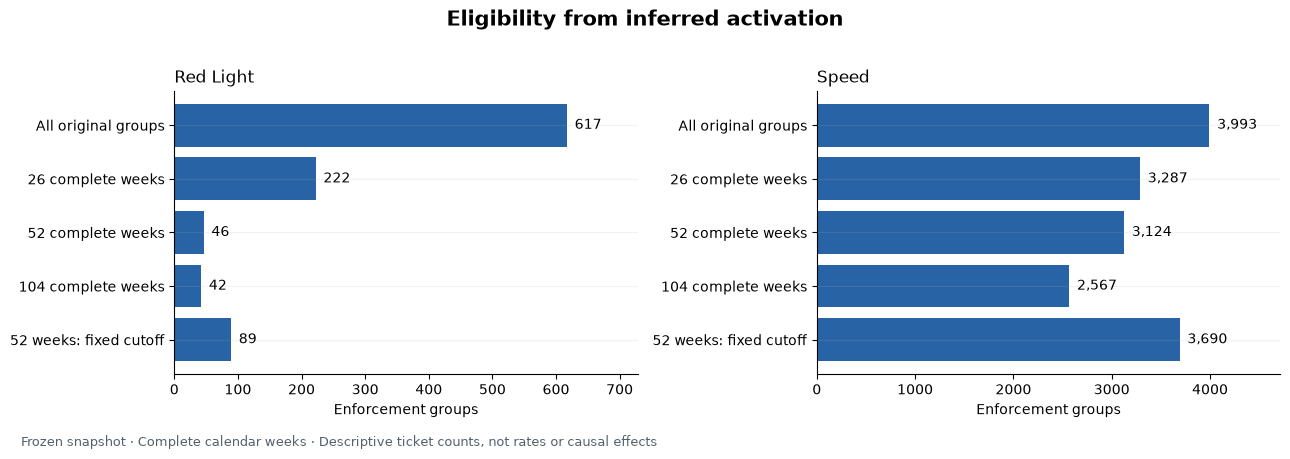

In [2]:
display(tables['coverage'])
display(tables['camera_eligibility'].groupby(['camera_type','exclusion_reason']).size().rename('Groups').reset_index())
plot_eligibility(tables, OUT)

## Results

### 3. Shared trajectories

Mean counts answer how many tickets a location records; normalized indices answer how a location changes relative to its own baseline. A large mean–median gap indicates concentration or heterogeneity.

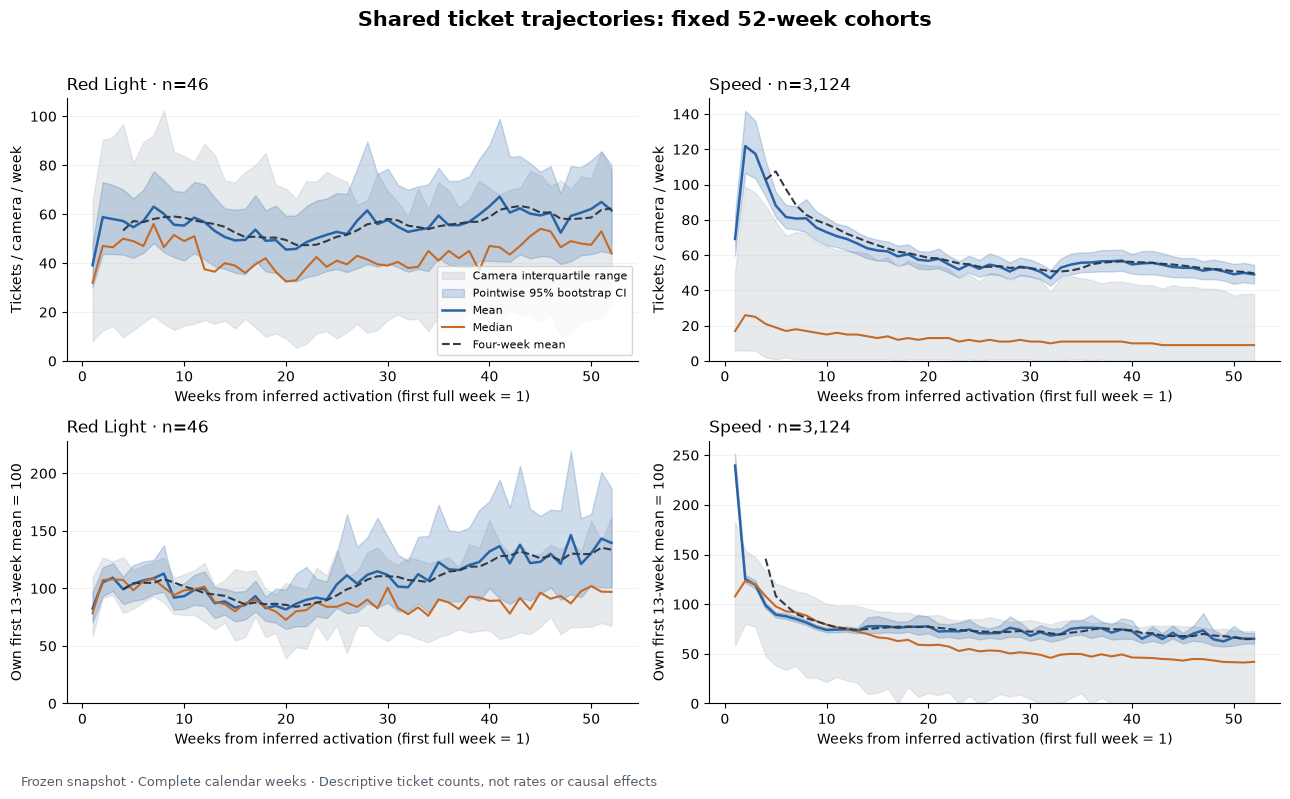

In [3]:
plot_shared(tables, OUT)

In [4]:
primary = tables['shared_trends'].query("scenario == 'balanced_52'")
comparison = []
for kind, frame in primary.groupby('camera_type'):
    first, last = frame[frame.week.le(13)], frame[frame.week.gt(39)]
    comparison.append({'Type':kind,'Raw cohort':int(frame.n.iloc[0]),'Indexed cohort':int(frame.index_n.iloc[0]),'First 13-week mean':first.raw_mean.mean(),'Last 13-week mean':last.raw_mean.mean(),'Last 13-week average index':last.index_mean.mean()})
display(pd.DataFrame(comparison).round(2))

,Type,Raw cohort,Indexed cohort,First 13-week mean,Last 13-week mean,Last 13-week average index
0,Red Light,46,46,55.99,61.14,131.25
1,Speed,3124,3124,84.40,52.41,67.52


### 4. Endpoint, confidence and activation-window sensitivities

These comparisons change the cohort or estimand, so disagreement is informative. The omit-first-four curve uses a weeks 5–17 baseline; it is not a continuation on the original index scale.

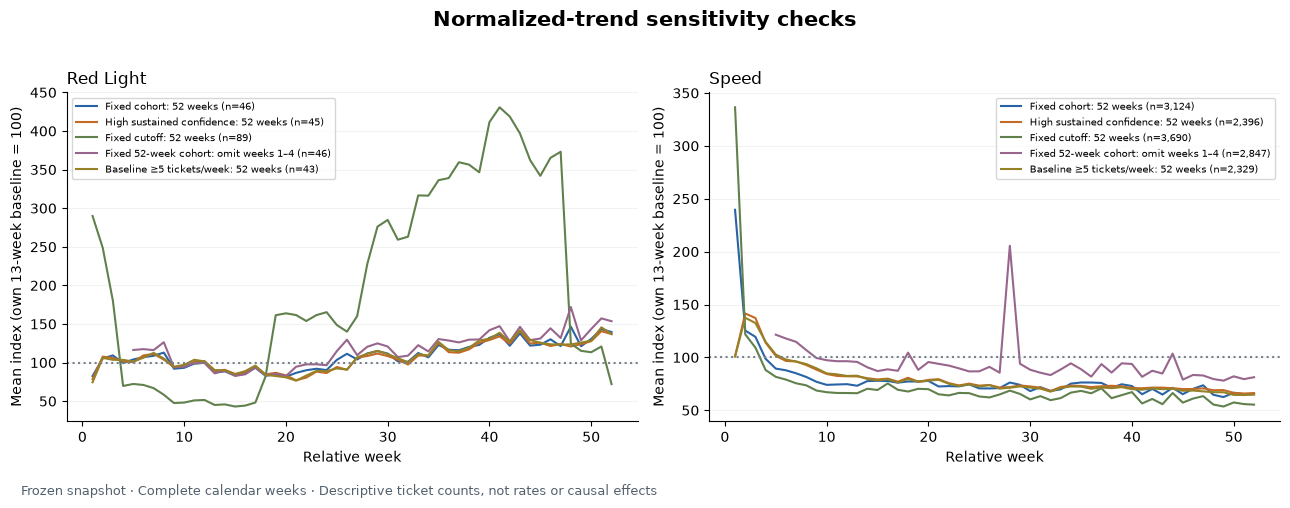

In [5]:
plot_sensitivities(tables, OUT)

### 5. Calendar-time and activation cohorts

The calendar view has changing membership; its contributing-camera count is shown explicitly. Activation-year comparisons remain descriptive and can differ in geography, traffic, policy, operation and ascertainment.

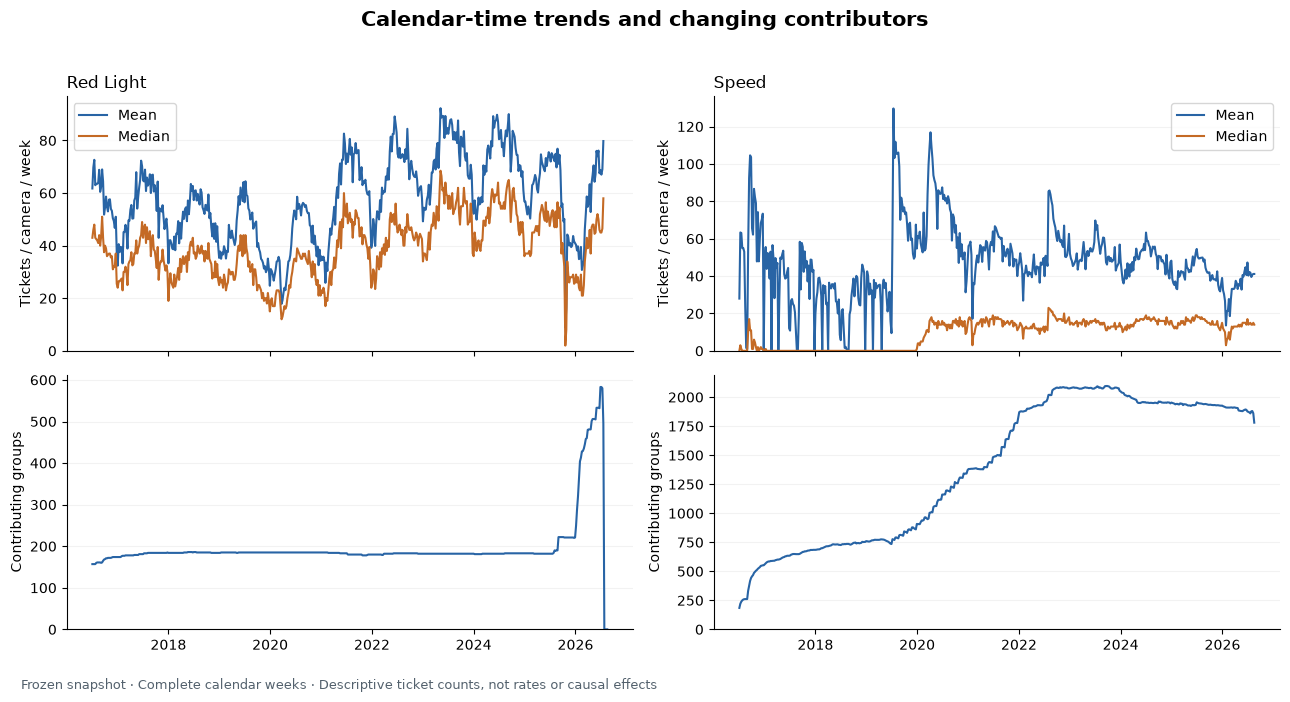

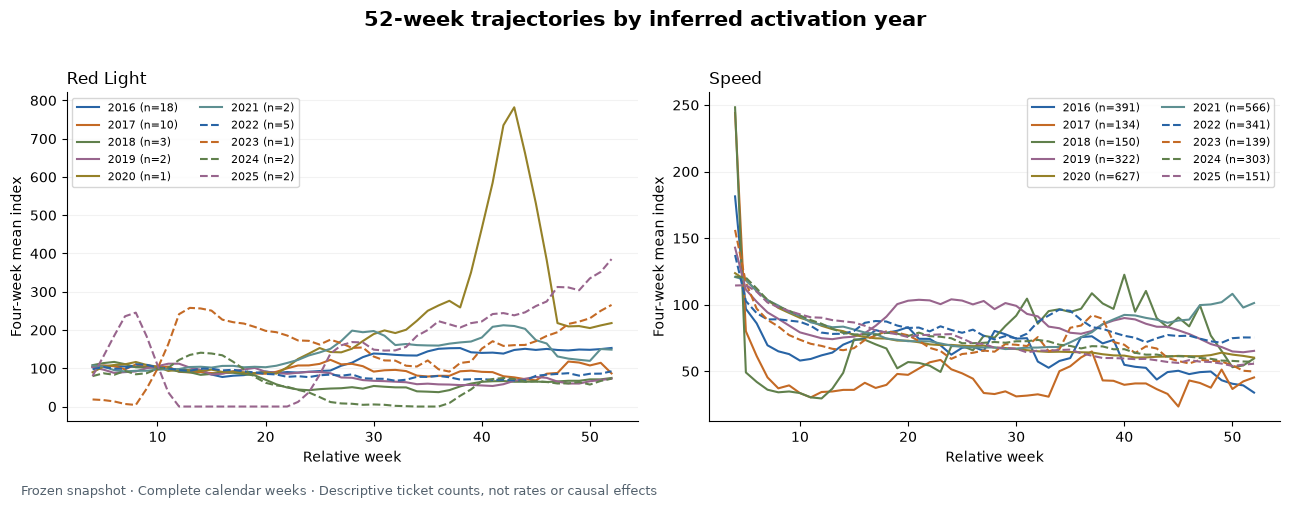

In [6]:
plot_calendar(tables, OUT)
plot_cohorts(tables, OUT)

### 6. Shape clusters and model selection

Cluster labels describe the fitted trajectory. They do not identify causal mechanisms or verified operational status. A stable partition is not proof of natural categories.

,k,groups,silhouette,stability_ari,stability_min_ari,smallest_cluster,eligible_solution,selected,camera_type
0,2,46,0.268,1.000,1.000,22,True,True,Red Light
1,3,46,0.222,0.691,0.437,13,False,False,Red Light
2,4,46,0.213,0.762,0.576,5,False,False,Red Light
3,5,46,0.198,0.643,0.491,3,False,False,Red Light
4,6,46,0.208,0.651,0.540,4,False,False,Red Light
5,2,3124,0.188,0.976,0.921,1209,False,False,Speed
6,3,3124,0.139,0.791,0.282,759,False,False,Speed
7,4,3124,0.138,0.825,0.567,537,False,False,Speed
8,5,3124,0.113,0.812,0.441,440,False,False,Speed
9,6,3124,0.115,0.903,0.761,325,False,False,Speed


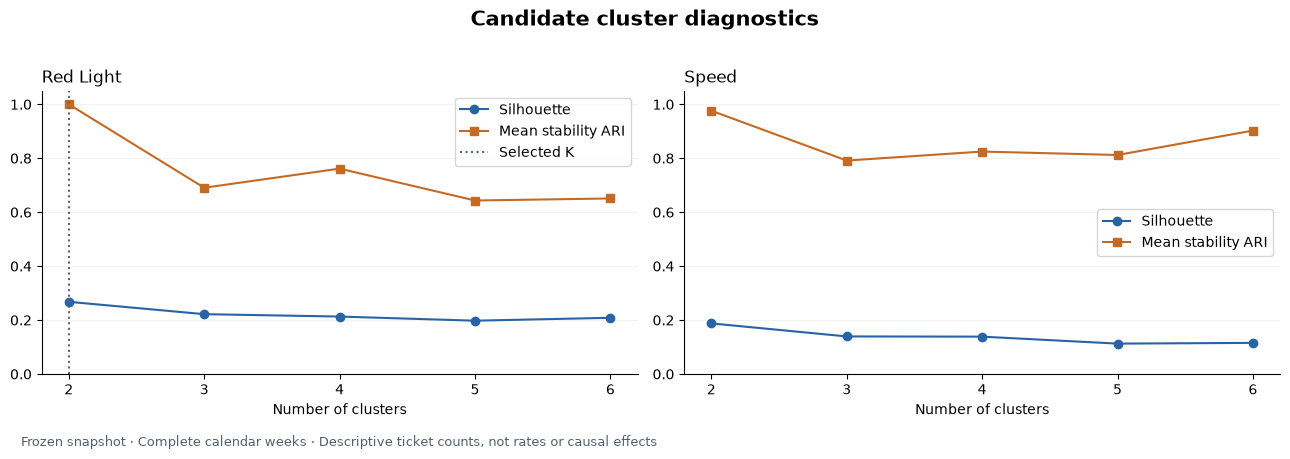

,camera_type,cluster_id,cluster_label,groups,median_weekly_tickets,median_change_pct,zero_week_fraction,high_confidence_groups,representative_ids
0,Red Light,red-light-1,C1: Declining,24,45.42,-35.16,0.06,24,cam_b98e56a34629a6b2;cam_2ee54c9155d9458b;cam_...
1,Red Light,red-light-2,C2: Increasing,22,43.33,39.22,0.05,21,cam_d26f9e9f75ac4931;cam_777037d6e7c8e7f6;cam_...


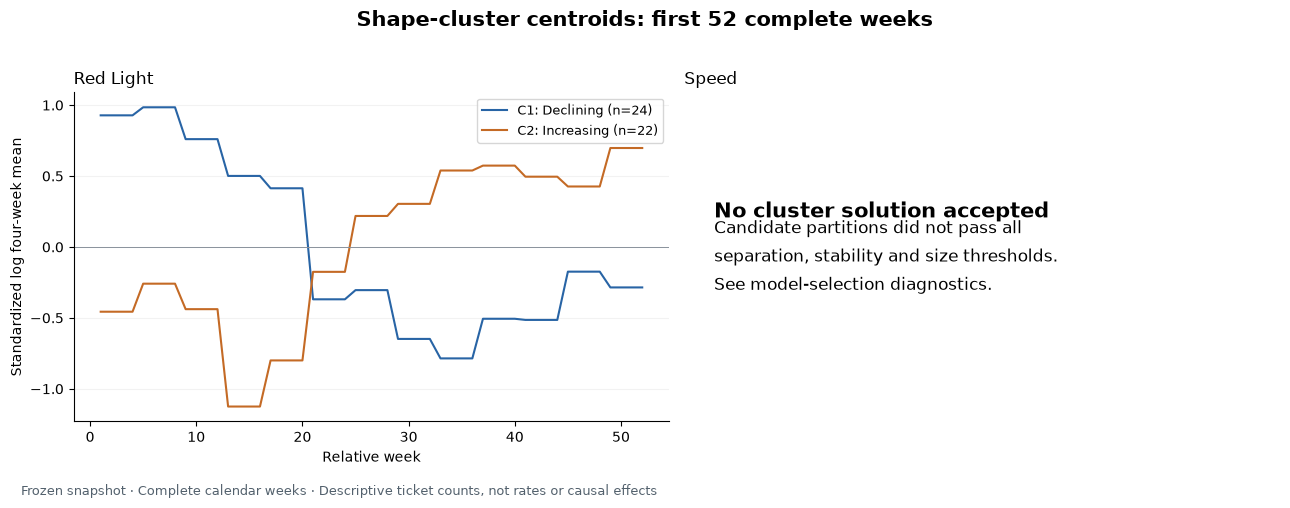

In [7]:
display(tables['cluster_diagnostics'].round(3))
plot_diagnostics(tables, OUT)
display(tables['cluster_profiles'].round(2))
plot_clusters(tables, OUT)

### 7. Cluster robustness and representative locations

Adjusted Rand index compares membership agreement, with 1 meaning identical assignments up to label names. Representatives are actual members nearest each centroid.

In [8]:
display(tables['cluster_sensitivity'].round(3))
representatives = tables['cluster_membership'].query('is_representative == True')
display(representatives[['camera_id','search_query','camera_type','cluster_label','weekly_mean_52w','detection_confidence']].round(2))
display(tables['cluster_composition'].head(16))

,camera_type,sensitivity,groups,ari,status
0,Red Light,Exclude sparse histories,46,1.00,Refit on subset
1,Red Light,High sustained confidence only,45,1.00,Refit on subset
2,Red Light,Omit first four weeks,46,0.83,Refit with weeks 5–52


,camera_id,search_query,camera_type,cluster_label,weekly_mean_52w,detection_confidence
816,cam_2ee54c9155d9458b,"BAY ST AND HANNA H ST, NEW YORK, NY",Red Light,C1: Declining,60.25,high_sustained
2134,cam_777037d6e7c8e7f6,"BRUCKNER BLVD AND BRONX RIVER PKWY R, NEW YORK...",Red Light,C2: Increasing,99.12,high_sustained
3299,cam_b98e56a34629a6b2,"UTOPIA PKWY AND HOR ACE HARDING EXPWY, NEW YOR...",Red Light,C1: Declining,6.54,high_sustained
3324,cam_ba9b9465ac701a3a,"FLATBUSH AVE AND AVIATOR SPORTS COMP, NEW YORK...",Red Light,C1: Declining,30.87,high_sustained
3365,cam_bd32f17e40df2857,"DITMAS AVE AND REMS EN AVE, NEW YORK, NY",Red Light,C2: Increasing,31.83,high_sustained
3770,cam_d26f9e9f75ac4931,"10TH AVE AND WES T 34TH ST, NEW YORK, NY",Red Light,C2: Increasing,35.69,high_sustained


,camera_type,cluster_id,cluster_label,activation_year,detection_confidence,groups
0,Red Light,red-light-1,C1: Declining,2016,high_sustained,7
1,Red Light,red-light-1,C1: Declining,2017,high_sustained,7
2,Red Light,red-light-1,C1: Declining,2018,high_sustained,3
3,Red Light,red-light-1,C1: Declining,2019,high_sustained,1
4,Red Light,red-light-1,C1: Declining,2022,high_sustained,4
5,Red Light,red-light-1,C1: Declining,2024,high_sustained,2
6,Red Light,red-light-2,C2: Increasing,2016,high_sustained,11
7,Red Light,red-light-2,C2: Increasing,2017,high_sustained,2
8,Red Light,red-light-2,C2: Increasing,2017,low_fallback,1
9,Red Light,red-light-2,C2: Increasing,2019,high_sustained,1


### 8. Reconciliation and provenance

In [9]:
display(tables['validation_checks'])
assert tables['validation_checks'].passed.all()
display(pd.DataFrame([{'Input':k,'SHA-256':v} for k,v in manifest['inputs'].items()]))

,check,passed
0,Unique original camera identifiers,True
1,Unique camera-week input keys,True
2,All original groups retained in eligibility,True
3,Activation dates unchanged,True
4,Primary observed counts nonnegative integers,True
5,Complete observed counts reconcile,True
6,Administrative panel does not lose covered pri...,True
7,Eligibility requires every anchored week,True
8,Every original group retained in cluster direc...,True
9,Cluster assignments unique,True


,Input,SHA-256
0,camera_summary.csv,1922873b06e09748006124a2b4b6f3f467f41920e3a183...
1,camera_weekly_trends.parquet,c462fb38133c193e672cb5b14f7ebb62dde403c37e9ccb...
2,reconciliation.json,78303cbde46cf112630e88fe58e43a7ed4df2de233cc78...
3,registry_pin.json,3d8d9b3e5c8bfd2497b8992db4dd9d0a1cb74f70c86c41...


## Takeaways

Read the mean, median, indexed trend and sensitivity views together. Clustering describes variation around the shared trend; an average can conceal opposite trajectories. All exclusions and original confidence labels are retained in `camera_eligibility.csv` and `cluster_membership.csv`. The accompanying dashboard provides the same aggregate tables and links cluster members back to their full original ticket histories. No result establishes reduced speeding, confirmed camera operation, or an effect on collisions.